In [1]:
!pip -q install opencv-python matplotlib numpy

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

print('Libraries imported successfully.')

Libraries imported successfully.


## Cell 2 — Upload and load a sample image

In [3]:
uploaded = files.upload()
image_path = next(iter(uploaded))

image_bgr = cv2.imread(image_path)
if image_bgr is None:
    raise ValueError('Unable to load the uploaded image. Please upload a JPG or PNG image.')

image = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
image = cv2.resize(image, (256, 256))
gray_image = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

print('Image loaded successfully.')
print('Image dimensions:', image.shape)

Saving Screenshot 2026-09-24 225052.png to Screenshot 2026-09-24 225052.png
Image loaded successfully.
Image dimensions: (256, 256, 3)


## Cell 3 — Display the original image

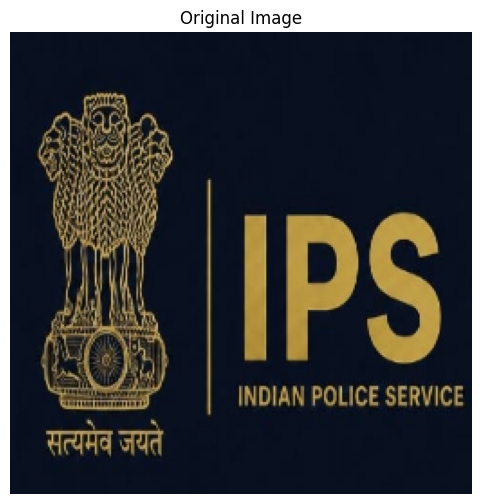

In [4]:
plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.title('Original Image')
plt.axis('off')
plt.show()

## Cell 4 — Define convolution filters

In [5]:
edge_kernel = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
], dtype=np.float32)

sharpen_kernel = np.array([
    [ 0, -1,  0],
    [-1,  5, -1],
    [ 0, -1,  0]
], dtype=np.float32)

blur_kernel = np.ones((3, 3), dtype=np.float32) / 9

print('Convolution kernels defined.')

Convolution kernels defined.


## Cell 5 — Apply convolution filters

In [6]:
edge_map = cv2.filter2D(gray_image, cv2.CV_32F, edge_kernel)
edge_map = np.clip(np.abs(edge_map), 0, 255).astype(np.uint8)

sharpened_image = cv2.filter2D(gray_image, -1, sharpen_kernel)
blurred_image = cv2.filter2D(gray_image, -1, blur_kernel)

print('Edge detection, sharpening, and blurring completed.')

Edge detection, sharpening, and blurring completed.


## Cell 6 — Visualize convolution results

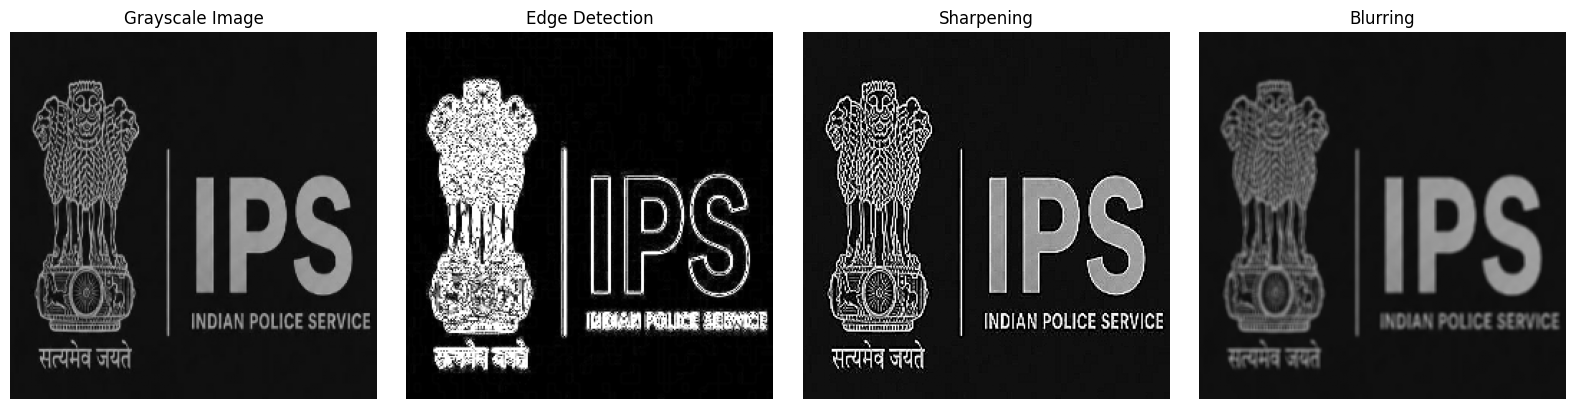

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
results = [
    (gray_image, 'Grayscale Image'),
    (edge_map, 'Edge Detection'),
    (sharpened_image, 'Sharpening'),
    (blurred_image, 'Blurring')
]

for ax, (img, title) in zip(axes, results):
    ax.imshow(img, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis('off')

plt.tight_layout()
plt.show()

## Cell 7 — Perform max pooling and average pooling

In [8]:
# Exact non-overlapping 2 x 2 pooling on the grayscale image.
# Crop to even dimensions so each pooling window is complete.
h, w = gray_image.shape
cropped = gray_image[:h - (h % 2), :w - (w % 2)]
blocks = cropped.reshape(cropped.shape[0] // 2, 2, cropped.shape[1] // 2, 2)

max_pool = blocks.max(axis=(1, 3)).astype(np.uint8)
average_pool = np.rint(blocks.mean(axis=(1, 3))).astype(np.uint8)

print('Original grayscale dimensions:', gray_image.shape)
print('Max pooling dimensions:', max_pool.shape)
print('Average pooling dimensions:', average_pool.shape)

Original grayscale dimensions: (256, 256)
Max pooling dimensions: (128, 128)
Average pooling dimensions: (128, 128)


## Cell 8 — Visualize pooling results

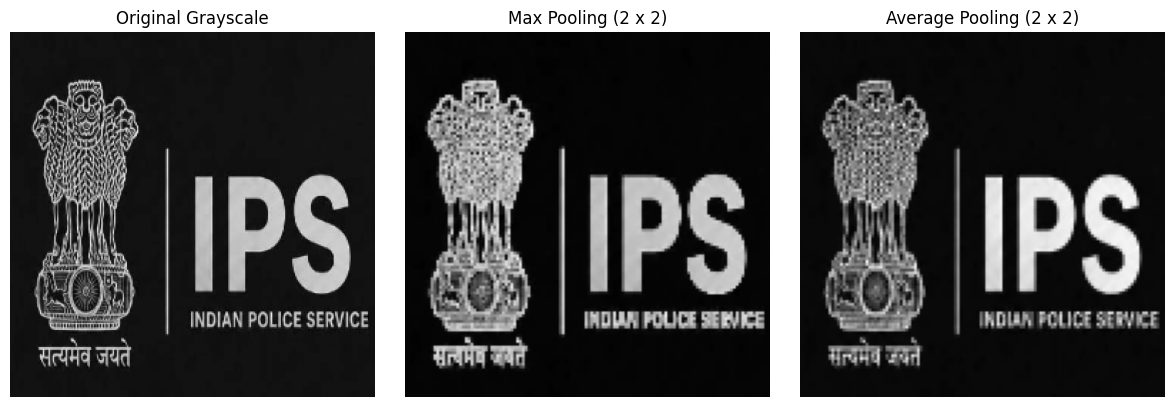

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(gray_image, cmap='gray')
axes[0].set_title('Original Grayscale')

axes[1].imshow(max_pool, cmap='gray')
axes[1].set_title('Max Pooling (2 x 2)')

axes[2].imshow(average_pool, cmap='gray')
axes[2].set_title('Average Pooling (2 x 2)')

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()

## Cell 9 — Compare all outputs

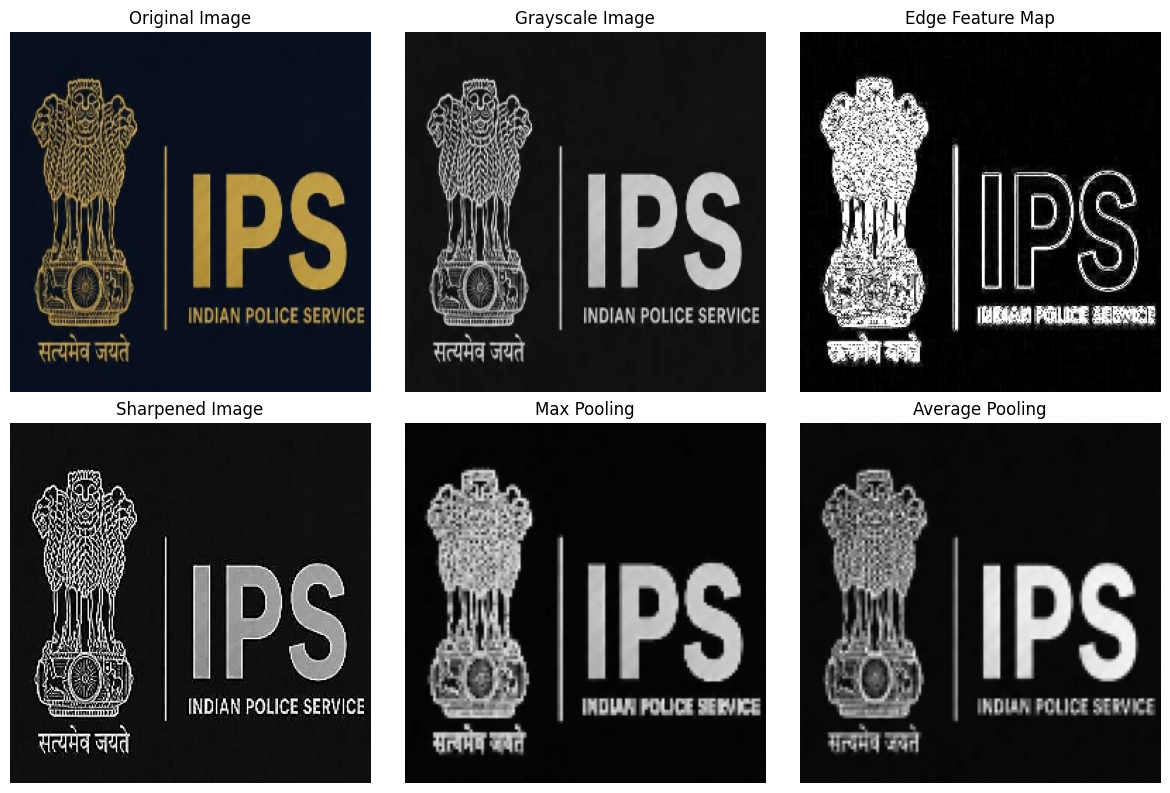

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
results = [
    (image, 'Original Image'),
    (gray_image, 'Grayscale Image'),
    (edge_map, 'Edge Feature Map'),
    (sharpened_image, 'Sharpened Image'),
    (max_pool, 'Max Pooling'),
    (average_pool, 'Average Pooling')
]

for ax, (img, title) in zip(axes.flat, results):
    if img.ndim == 3:
        ax.imshow(img)
    else:
        ax.imshow(img, cmap='gray')
    ax.set_title(title)
    ax.axis('off')

plt.tight_layout()
plt.show()